In [83]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [84]:
months=["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
sales=[87282, 27670, 56628, 49694, 78025, 98398, 65949, 71307, 31409,
       83150, 960163, 21708]

In [85]:
sales

[87282,
 27670,
 56628,
 49694,
 78025,
 98398,
 65949,
 71307,
 31409,
 83150,
 960163,
 21708]

In [86]:
df=pd.DataFrame({
    "months":months,
    "sales":sales,
})

In [87]:
df.head(12)

,months,sales
0,jan,87282
1,feb,27670
2,mar,56628
3,apr,49694
4,may,78025
5,jun,98398
6,jul,65949
7,aug,71307
8,sep,31409
9,oct,83150


In [88]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   months  12 non-null     str  
 1   sales   12 non-null     int64
dtypes: int64(1), str(1)
memory usage: 360.0 bytes


In [89]:
df.describe()

,sales
count,12.000000
mean,135948.583333
std,260727.041212
min,21708.000000
25%,45122.750000
50%,68628.000000
75%,84183.000000
max,960163.000000


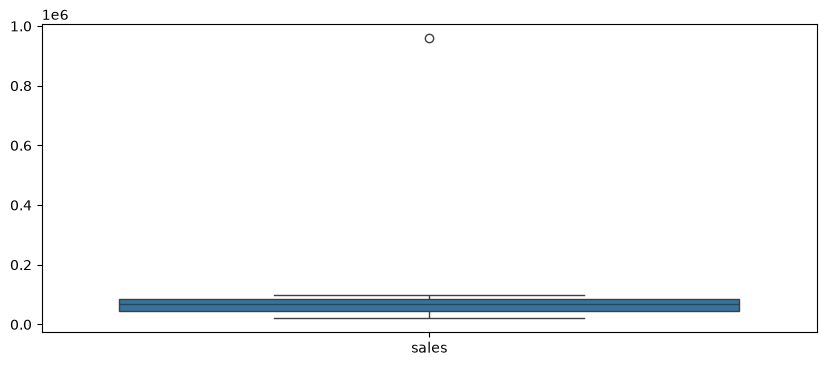

In [90]:
plt.figure(figsize=(10,4))
sns.boxplot(df)
plt.show()

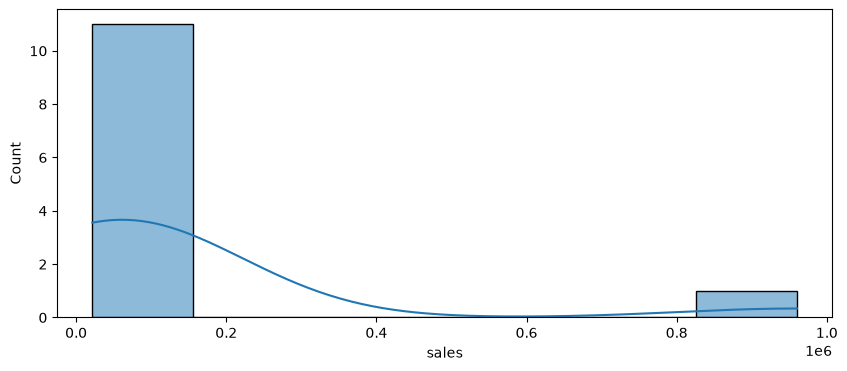

In [91]:
plt.figure(figsize=(10,4))
sns.histplot(df["sales"],kde=True)
plt.show()

In [92]:
# IQR - Inter Quantile Range
# IQR= Q3-Q1
# Q3= 75th percentile value
# Q1= 25th percentile value
# min_value,max_value
# min_value=Q1-1.5*IQR
# max_value=Q3+1.5*IQR


In [93]:
Q1=df["sales"].quantile(0.25)
Q3=df["sales"].quantile(0.75)
Q1,Q3

(np.float64(45122.75), np.float64(84183.0))

In [94]:
IQR=Q3-Q1
IQR

np.float64(39060.25)

In [95]:
min_value=Q1-1.5*IQR
max_value=Q3+1.5*IQR

In [96]:
min_value,max_value

(np.float64(-13467.625), np.float64(142773.375))

In [97]:
df_free_outlier=df[df["sales"]<max_value]

In [98]:
df_free_outlier.head()

,months,sales
0,jan,87282
1,feb,27670
2,mar,56628
3,apr,49694
4,may,78025


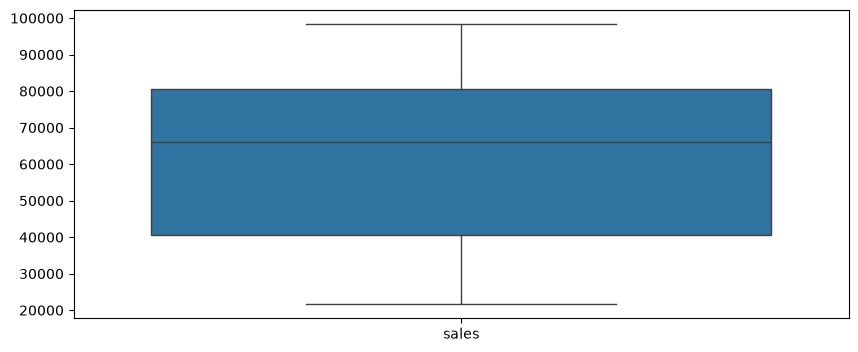

In [99]:
plt.figure(figsize=(10,4))
sns.boxplot(df_free_outlier)
plt.show()

In [100]:
df.head(12)

,months,sales
0,jan,87282
1,feb,27670
2,mar,56628
3,apr,49694
4,may,78025
5,jun,98398
6,jul,65949
7,aug,71307
8,sep,31409
9,oct,83150


In [101]:
# Z score
# mean=0,std=1
new_df=df.copy()

In [105]:
new_df.head(12)

,months,sales
0,jan,87282
1,feb,27670
2,mar,56628
3,apr,49694
4,may,78025
5,jun,98398
6,jul,65949
7,aug,71307
8,sep,31409
9,oct,83150


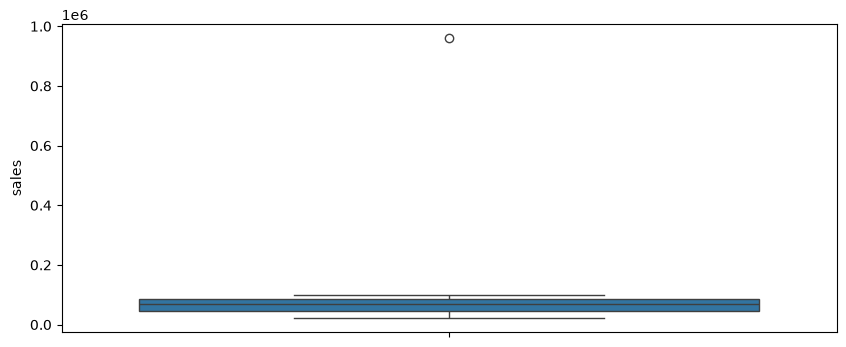

In [106]:
plt.figure(figsize=(10,4))
sns.boxplot(new_df["sales"])
plt.show()

In [107]:
new_df["Z_score"]=(df["sales"]-df["sales"].mean())/df["sales"].std()

In [108]:
new_df

,months,sales,Z_score
0,jan,87282,-0.186657
1,feb,27670,-0.415295
2,mar,56628,-0.304228
3,apr,49694,-0.330823
4,may,78025,-0.222162
5,jun,98398,-0.144023
6,jul,65949,-0.268478
7,aug,71307,-0.247928
8,sep,31409,-0.400954
9,oct,83150,-0.202505


In [112]:
new_df=new_df[new_df["Z_score"]<3 ]

In [113]:
new_df

,months,sales,Z_score
0,jan,87282,-0.186657
1,feb,27670,-0.415295
2,mar,56628,-0.304228
3,apr,49694,-0.330823
4,may,78025,-0.222162
5,jun,98398,-0.144023
6,jul,65949,-0.268478
7,aug,71307,-0.247928
8,sep,31409,-0.400954
9,oct,83150,-0.202505


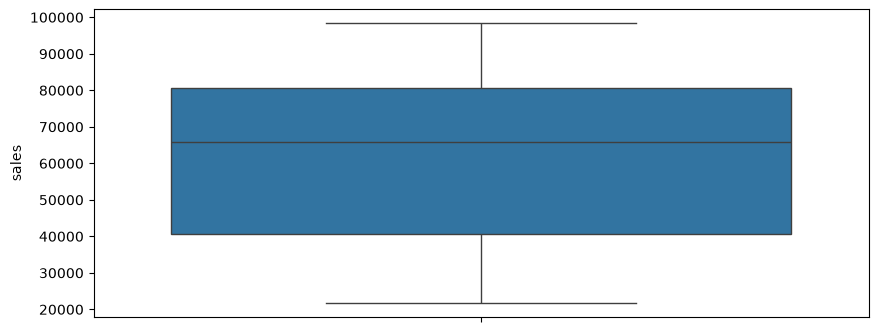

In [114]:
plt.figure(figsize=(10,4))
sns.boxplot(new_df["sales"])
plt.show()